# Case de tráfego

**Oficina Visão Computacional para Cidades Inteligentes**
Semana do Urbanismo de Canaã dos Carajás, 11/11/2026

Vamos fazer uma câmera de trânsito virar dados de cidade. Num cruzamento de Bellevue (EUA), o computador vai **detectar** os veículos, **rastrear** cada um ao longo de 40 segundos e contar **de onde veio e para onde foi**. O resultado é a **Matriz de movimentos**, a mesma tabela que um engenheiro de tráfego usa para regular um semáforo.

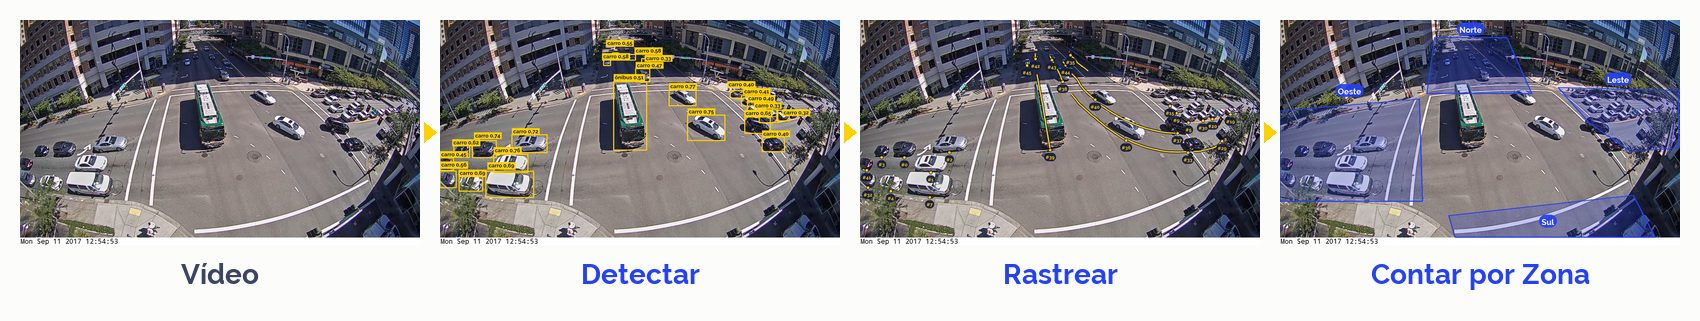

Rode as células **na ordem, de cima para baixo**, acompanhando o projetor. Para rodar uma célula, clique no ▶ à esquerda dela (ou aperte Shift + Enter).

| Etapa | O que acontece |
|---|---|
| 0 | Preparar o ambiente |
| 1 | A imagem é uma matriz de números |
| 2 | Detectar os veículos na Cena-âncora |
| 3 | Mexer no limiar de confiança |
| 4 | Desenhar as Zonas por Aproximação |
| 5 | Rastrear e contar os 40 segundos |
| 6 | Pular: usar o Resultado pronto |
| 7 | Assistir e ler o vídeo de saída |

# 0. Preparar o ambiente

Baixa o código da Oficina, instala os pacotes e baixa o vídeo, a Cena-âncora e o modelo. Leva cerca de 1 minuto e termina com uma checklist ✅.

In [ ]:
#@title 0. Preparar o ambiente
import os, sys, subprocess
if "google.colab" in sys.modules:
    PASTA = "/content/oficina-vc-canaa"
    if not os.path.isdir(PASTA + "/.git"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", "v2026.11.11",
                        "https://github.com/andrematte/oficina-vc-canaa", PASTA], check=True)
else:
    PASTA = os.path.abspath(".")  # Modo local: o notebook roda de dentro do repositório
if PASTA not in sys.path:
    sys.path.insert(0, PASTA)
from oficina_vc import preparar
preparar("case")

# 1. A imagem é uma matriz de números

Esta é a **Cena-âncora**, o quadro do cruzamento que acompanhou a teoria. Para o computador, ela é uma matriz de números: uma linha para cada fileira de pixels, uma coluna para cada pixel e três números por pixel, um para cada cor (de 0 a 255).

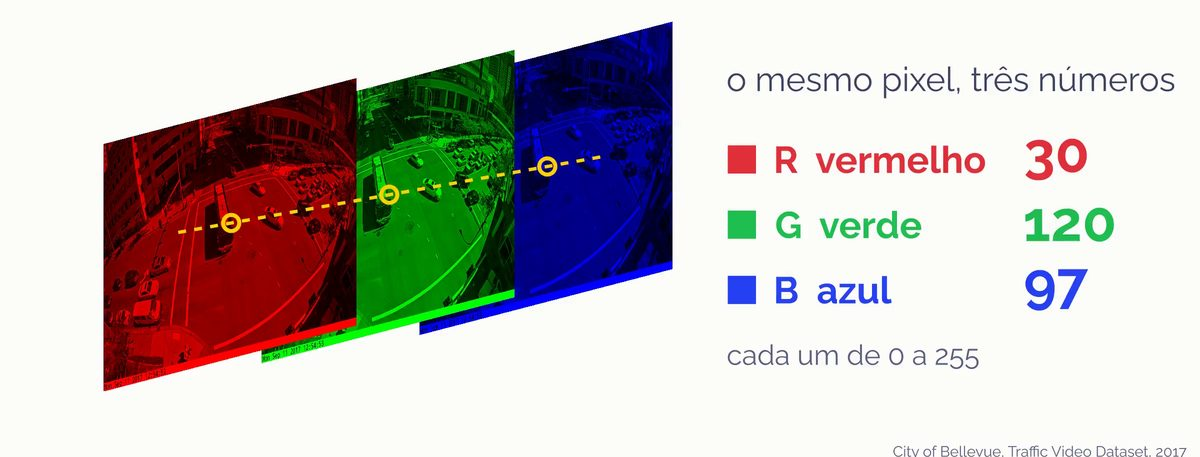

O pixel abaixo é o mesmo da teoria, na lateral do ônibus. Só muda a ordem: o OpenCV guarda as cores como **azul, verde, vermelho**.

> **Como ler o código**
> - `nome = valor` guarda um valor com um nome, para usar depois;
> - `funcao(...)` faz uma ação; entre parênteses vão as opções dela;
> - `print(...)` escreve um resultado na tela;
> - depois do `#` vem um comentário, que o computador ignora.

In [ ]:
import cv2
from oficina_vc import caminho, mostrar

quadro = cv2.imread(str(caminho("cena_ancora_bellevue_623.png")))  # lê a foto como tabela de números
mostrar(quadro)

In [ ]:
print("Formato:", quadro.shape, " (altura, largura, cores)")
print("Pixel da linha 326, coluna 645:", quadro[326, 645], " (azul, verde, vermelho)")
print("Um pedaço de 5 × 5 pixels em volta dele, só o verde:")
print(quadro[324:329, 643:648, 1])  # linhas 324 a 328, colunas 643 a 647, cor 1 (verde)

### Experimente: recortar a imagem

Um recorte é um pedaço da tabela: `quadro[linha_inicial:linha_final, coluna_inicial:coluna_final]`. Arraste os controles para mover o recorte e mudar o tamanho dele. Com um tamanho pequeno, os pixels aparecem como quadradinhos.

In [ ]:
#@title Recortar a imagem { run: "auto" }
LINHA = 190 #@param {type:"slider", min:0, max:710, step:10}
COLUNA = 520 #@param {type:"slider", min:0, max:1270, step:10}
TAMANHO = 240 #@param {type:"slider", min:5, max:400, step:5}

from oficina_vc import mostrar_recorte

recorte = quadro[LINHA:LINHA + TAMANHO, COLUNA:COLUNA + TAMANHO]  # as linhas e as colunas do recorte
print("Formato do recorte:", recorte.shape, " (altura, largura, cores)")
mostrar_recorte(quadro, recorte, LINHA, COLUNA)

### Experimente: trocar a ordem das cores

Quem mostra a imagem lê as três camadas sempre na ordem azul, verde, vermelho. Escolha outra ordem na lista: os números continuam os mesmos, só muda a camada em que cada um é lido.

In [ ]:
#@title Trocar a ordem das cores { run: "auto" }
ORDEM = "vermelho, verde, azul" #@param ["azul, verde, vermelho", "vermelho, verde, azul", "verde, azul, vermelho", "azul, vermelho, verde", "verde, vermelho, azul", "vermelho, azul, verde"]

CAMADA = {"azul": 0, "verde": 1, "vermelho": 2}  # a posição de cada cor na tabela
ordem = [CAMADA[cor] for cor in ORDEM.split(", ")]
trocado = quadro[:, :, ordem]  # as mesmas camadas, em outra ordem
print("Pixel do ônibus:", trocado[326, 645])
mostrar(trocado)

# 2. Detectar os veículos na Cena-âncora

Agora um **modelo pré-treinado** procura veículos na matriz de números, em quatro passos: carregar o modelo, rodá-lo na Cena-âncora, ler a resposta e desenhar as caixas.

### 2.1 Carregar o modelo

O modelo aprendeu com o **COCO** (*Common Objects in Context*, 2014), um conjunto de cerca de 118 mil fotos do dia a dia com 860 mil caixas desenhadas à mão, em **80 classes**: pessoa, carro, ônibus, semáforo, cachorro, pizza… Para o modelo, cada classe é um número:

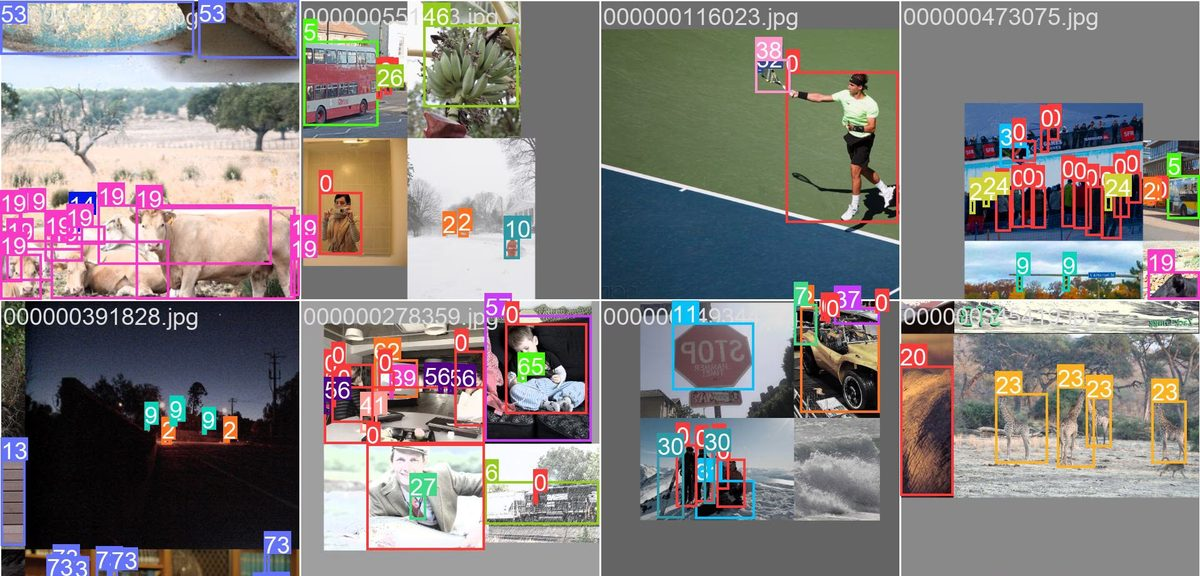

<sub>Um lote de treino do COCO: cada caixa leva o número da classe (0 = pessoa, 2 = carro, 5 = ônibus, 9 = semáforo). Imagem: Ultralytics, docs.ultralytics.com.</sub>

O modelo é o **YOLO26n**. YOLO (*You Only Look Once*, "você só olha uma vez") é uma família de detectores que acha todas as caixas numa passada só pela imagem, rápido o bastante para vídeo. A versão 26 (Ultralytics, janeiro de 2026) vem em cinco tamanhos:

| Tamanho | Pesos | Nota no COCO (mAP) | Tempo na CPU |
|---|---|---|---|
| **n** (nano) | 2,5 milhões | 40,9 | 1× |
| s (small) | 9,5 milhões | 48,6 | 2× |
| m (medium) | 20 milhões | 53,1 | 6× |
| l (large) | 25 milhões | 55,0 | 7× |
| x (extra large) | 56 milhões | 57,5 | 14× |

<sub>Fonte: docs.ultralytics.com/models/yolo26. mAP é a nota de acerto das caixas, de 0 a 100.</sub>

Usamos o **n**, o menor: acerta menos que os grandes, mas roda na CPU do Colab no tempo da aula. Para trocar de tamanho, basta trocar o arquivo (`yolo26s.pt`, `yolo26m.pt`…).

In [ ]:
from ultralytics import YOLO
from oficina_vc import resumo_do_modelo

modelo = YOLO(str(caminho("yolo26n.pt")))  # o arquivo .pt guarda os pesos aprendidos no COCO
resumo_do_modelo(modelo)
print("\nAs 80 classes do COCO, cada uma com o seu número:")
print(modelo.names)

### 2.2 Rodar o modelo na Cena-âncora

- `classes=VEICULOS`: só as 4 classes de veículo do COCO. Repare nos nomes: não existe "pickup" nem "van";
- `conf=0.25`: só as caixas com confiança de pelo menos 0,25;
- `imgsz=960`: o tamanho em que o modelo enxerga a imagem (maior acha mais veículos pequenos, lá no fundo, e demora mais).

In [ ]:
VEICULOS = [2, 3, 5, 7]  # os números das classes de veículo
print("Classes de veículo:", {i: modelo.names[i] for i in VEICULOS})

deteccoes = modelo(quadro, classes=VEICULOS, conf=0.25, imgsz=960, verbose=False)
print(f"O modelo encontrou {len(deteccoes[0].boxes)} veículos.")

### 2.3 Ler a resposta

A resposta do modelo também é uma matriz de números. Para cada caixa: a classe, a **confiança** de 0 a 1 (a nota da camada de classificação, como o "ônibus 0,51" da teoria) e dois cantos, `(x1, y1)` em cima à esquerda e `(x2, y2)` embaixo à direita.

In [ ]:
from oficina_vc import tabela_de_caixas

tabela_de_caixas(deteccoes)

### 2.4 Desenhar as caixas

Os mesmos números, agora desenhados sobre a foto. Que classe o modelo dá à van branca da esquerda?

In [ ]:
from oficina_vc import desenhar_caixas

mostrar(desenhar_caixas(quadro, deteccoes))

# 3. Mexer no limiar de confiança

O limiar decide a partir de que confiança uma caixa conta.

- Limiar **baixo**: o modelo acha mais veículos, mas começa a ver veículos onde não há (falsos positivos) ou duas caixas no mesmo carro.
- Limiar **alto**: sobram só as caixas certeiras, e os carros pequenos do fundo somem (falsos negativos).

### 3.1 Arrastar o limiar

Arraste o controle e veja as caixas mudarem. A célula roda sozinha a cada mudança.

In [ ]:
#@title 3. Limiar de confiança { run: "auto" }
CONFIANCA = 0.25 #@param {type:"slider", min:0.05, max:0.95, step:0.05}

deteccoes = modelo(quadro, classes=VEICULOS, conf=CONFIANCA, imgsz=960, verbose=False)
print(f"Limiar {CONFIANCA:.2f}: {len(deteccoes[0].boxes)} veículos.")
mostrar(desenhar_caixas(quadro, deteccoes))

### 3.2 Todos os limiares de uma vez

O modelo roda uma vez só, com o limiar mais baixo, e contamos quantas caixas passam em cada limiar. Cada █ é um veículo.

In [ ]:
confiancas = modelo(quadro, classes=VEICULOS, conf=0.05, imgsz=960, verbose=False)[0].boxes.conf

for limiar in [0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85]:
    n = int((confiancas >= limiar).sum())  # quantas caixas têm confiança de pelo menos `limiar`
    print(f"{limiar:.2f}  {'█' * n} {n}")

Que valor parece justo para contar este cruzamento?

<details><summary><b>Resposta</b></summary>

Não há um valor certo: depende de qual erro custa mais. Para contar tráfego, perder um veículo estraga a Matriz. Por isso a etapa 5 junta dois limiares: o rastreador só cria um veículo novo com confiança de pelo menos 0,45, mas aceita caixas fracas, a partir de 0,05, para não perder de vista quem já está sendo seguido.

</details>

# 4. Desenhar as Zonas por Aproximação

Para virar indicador, a detecção precisa de um lugar no espaço. O cruzamento tem quatro **Aproximações**, os braços por onde os veículos chegam e saem: Norte (em cima), Leste (à direita), Sul (embaixo) e Oeste (à esquerda). Cada uma ganha uma **Zona**, um polígono desenhado sobre a pista.

A regra da contagem:

- a Zona onde o veículo aparece primeiro é a **origem**;
- a próxima Zona em que ele entra é o **destino**;
- o par origem → destino é o **Movimento** dele. Quem volta para a própria Zona fez um **Retorno**.

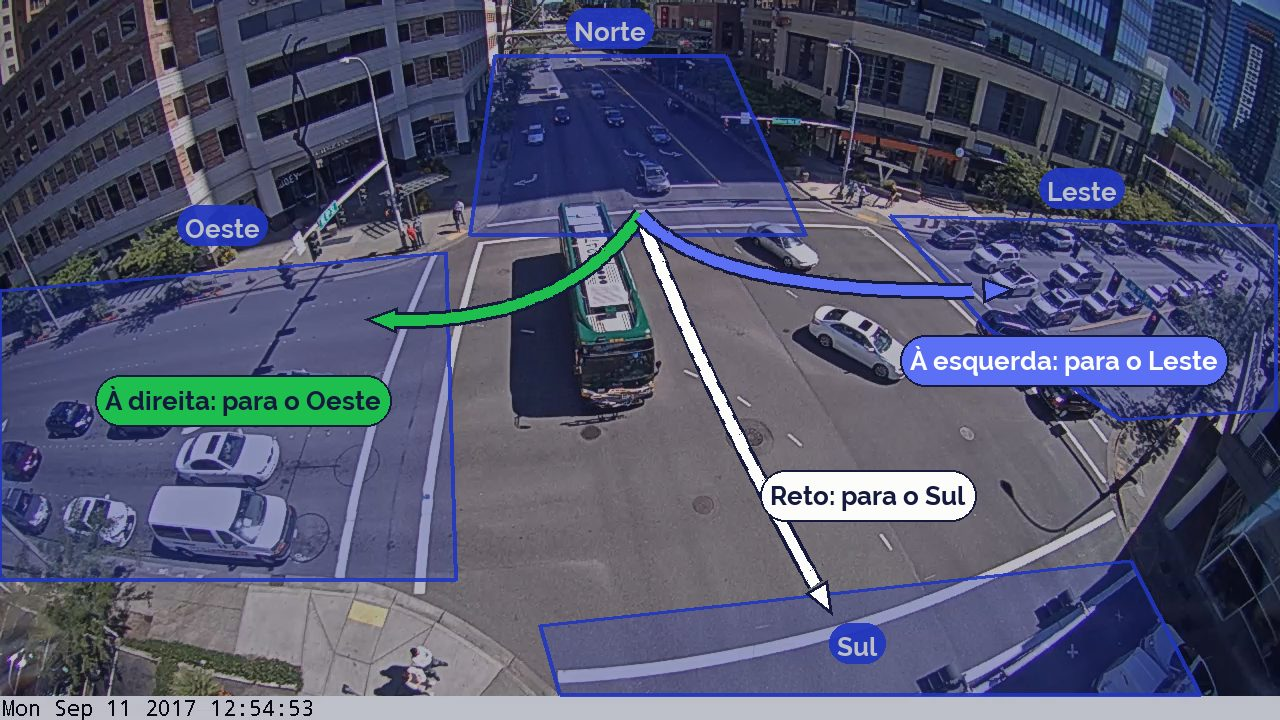

As posições são pixels `(x, y)`: `x` cresce para a direita e `y` cresce **para baixo**, a partir do canto de cima à esquerda. A conta é feita pelo ponto do meio da base de cada caixa, os "pés" do veículo.

In [ ]:
from oficina_vc import criar_zonas, desenhar_zonas

ZONAS = {                                                           # vértices de cada Zona
    "Norte": [(495, 55), (725, 55), (805, 235), (470, 235)],
    "Leste": [(890, 215), (1275, 225), (1275, 410), (1120, 420), (990, 330)],
    "Sul":   [(540, 625), (1130, 560), (1200, 695), (560, 695)],
    "Oeste": [(0, 290), (445, 252), (455, 580), (0, 580)],
}

zonas = criar_zonas(ZONAS)
mostrar(desenhar_zonas(quadro, zonas))

Para casa: troque os números de `ZONAS`, rode esta célula para ver onde ficaram e rode a etapa 5 de novo. Os nomes das Zonas precisam continuar Norte, Leste, Sul e Oeste: é deles que sai o nome de cada Movimento.

# 5. Rastrear e contar os 40 segundos

Agora o vídeo inteiro: 40 segundos de câmera fixa. Para cada quadro, o computador:

1. **detecta** os veículos, como na etapa 2;
2. **rastreia**: liga cada caixa ao mesmo veículo do quadro anterior e dá a ele um número, o **ID**;
3. **conta**: anota a Zona de origem de cada ID e, quando ele chega a outra Zona, soma um Movimento na **Matriz de movimentos**;
4. desenha tudo e grava o **vídeo de saída**, com o painel de Métricas de vídeo ao lado.

Algumas escolhas para caber no tempo da aula:

- `passo=2`: analisa 1 quadro a cada 2 (metade do trabalho, a mesma Matriz);
- `confianca=0.05`: o rastreador (ByteTrack) aceita caixas fracas, mas só para continuar o rastro de um veículo que já foi visto com confiança. É isso que segura o ID do carro meio escondido atrás do ônibus ou na curva.

<details><summary><b>Quer saber mais? Como o rastreador sabe que é o mesmo carro</b></summary>

Pela velocidade de cada veículo, ele prevê onde o veículo vai estar no quadro seguinte e liga cada caixa nova à previsão que ela mais cobre. Caixa sem par vira um veículo novo; veículo sem caixa espera até 1 segundo antes de ser esquecido. Quando dois veículos se cruzam ou um some atrás do ônibus, os números podem trocar: é a troca de ID da etapa 7.

</details>

Leva alguns minutos (a barra mostra quanto falta). **Se a barra estiver lenta demais, não espere**: clique no ■ ao lado desta célula para interromper e rode a etapa 6.

In [ ]:
from oficina_vc import criar_rastreador, processar_video

rastreador = criar_rastreador()

resultado = processar_video(
    caminho("bellevue-ne8th_2762-2802s.mp4"),
    modelo,
    rastreador,
    zonas,
    confianca=0.05,
    classes=VEICULOS,
    imgsz=960,
    passo=2,
)
resultado.resumo()

# 6. Pular: usar o Resultado pronto

**Só se a etapa 5 não terminou.** O Resultado pronto é o mesmo processamento, feito antes da Oficina, com os mesmos números. Rode esta célula e siga para a etapa 7.

In [ ]:
#@title 6. Pular: usar o Resultado pronto
from oficina_vc import resultado_pronto

resultado = resultado_pronto()
resultado.resumo()

# 7. Assistir e ler o vídeo de saída

À esquerda, o cruzamento com as caixas e os **Rastros** (o caminho dos últimos 2 segundos de cada veículo). Cada etiqueta mostra o ID e o Movimento: `#12 N→` já tem origem no Norte; `#12 N→L` foi contado como Norte → Leste. À direita, o painel de **Métricas de vídeo**, com a Matriz de movimentos enchendo ao vivo.

In [ ]:
from oficina_vc import mostrar_video

mostrar_video(resultado)

Leia o vídeo com o painel:

1. **Matriz de movimentos**: de qual Aproximação vem a maior parte dos veículos? Quantos seguem reto e quantos convertem?
2. **Do número à decisão**: o que essa Matriz justifica no semáforo? Pense no tempo de verde de cada Aproximação e na seta de conversão à esquerda.
3. **Ache o ônibus**: entre 17 s e 21 s, um ônibus verde e branco desce do Norte para o Sul. Ele entrou na Matriz como ônibus?
4. **Troca de ID**: olhe a esquina de cima à esquerda, onde quem vem do Norte converte para o Oeste. Algum veículo troca de número na curva? O que acontece com o Movimento dele na Matriz?
5. **Parados no semáforo**: as filas do Oeste e do Leste ficam paradas quase o vídeo todo. Elas entram na Matriz? Por quê?

<details><summary><b>Respostas</b></summary>

1. Do **Norte**: 32 dos 38 Movimentos. Só 8 seguem reto; 30 convertem, 22 deles à esquerda.
2. Mais tempo de verde para o Norte e uma seta própria para a conversão à esquerda Norte → Leste, que sozinha é metade do cruzamento (19 de 38). Para decidir de verdade, conta-se a hora de pico inteira, não 40 segundos.
3. Sim: 1 ônibus em Norte → Sul. Todo o resto é "carro".
4. Quando o rastreador perde o veículo na curva, ele ganha um número novo, que nasce sem origem e não vira Movimento. Por isso a Zona Oeste vai até a esquina. Mesmo assim, a Matriz conta 5 Norte → Oeste, e passaram 6.
5. Não: só vira Movimento quem sai de uma Zona e entra em outra. Para medir fila, a Métrica de vídeo é outra: a ocupação de cada Zona.

</details>

**E se quisermos saber _que tipo_ de veículo passa?** A Matriz diz que quase tudo é "carro": a van de serviço com escada no teto (3 s a 8 s, Norte → Oeste), o caminhão-plataforma (5 s a 10 s, Norte → Leste) e as pickups entram como carro, porque o modelo só conhece as classes com que foi treinado. Para uma contagem de tráfego, essa diferença pesa (pavimento, vagas de carga, emissões). É o que o próximo notebook ensina, com fine-tuning: separar Carro, Pickup, Van, Caminhão e Ônibus.

Para guardar suas mudanças: **Arquivo › Salvar uma cópia no Drive**.

<sub>Imagens: slides da Oficina (CC BY-NC-SA 4.0); lote de treino do COCO: Ultralytics, docs.ultralytics.com (AGPL-3.0). Vídeo e quadros: City of Bellevue, Traffic Video Dataset, 2017 (ver `LICENCA-VIDEO.md`).</sub>